<a href="https://colab.research.google.com/github/kiet26b21a4228-svg/Sai-kumar/blob/main/Kirchhof's_circute_solver_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

        KIRCHHOFF'S CIRCUIT SOLVER
Enter the circuit values below.
All resistances are in Ohms (Ω) and voltages are in Volts (V).

RESISTANCE VALUES
----------------------------------------
Enter R1  (Ω): 5
Enter R2  (Ω): 6
Enter R3  (Ω): 8
Enter R12 (Ω): 4
Enter R23 (Ω): 6
Enter R13 (Ω): 2

VOLTAGE SOURCE VALUES
----------------------------------------
Enter V1 (V): 7
Enter V2 (V): 4
Enter V3 (V): 6

                 INPUT VALUES
R1  = 5.00 Ω
R2  = 6.00 Ω
R3  = 8.00 Ω
R12 = 4.00 Ω
R23 = 6.00 Ω
R13 = 2.00 Ω
V1  = 7.00 V
V2  = 4.00 V
V3  = 6.00 V

                 KVL EQUATIONS
11.00I1 -4.00I2 -2.00I3 = 7.00
-4.00I1 +16.00I2 -6.00I3 = 4.00
-2.00I1 -6.00I2 +16.00I3 = 6.00

              AUGMENTED MATRIX [A | V]
[[11. -4. -2.  7.]
 [-4. 16. -6.  4.]
 [-2. -6. 16.  6.]]

              GAUSS-JORDAN RREF
[[1.       0.       0.       1.087824]
 [0.       1.       0.       0.830339]
 [0.       0.       1.       0.822355]]

                 CIRCUIT CURRENTS
I1 = 1.087824 A
I2 = 0.830339 A
I3 = 

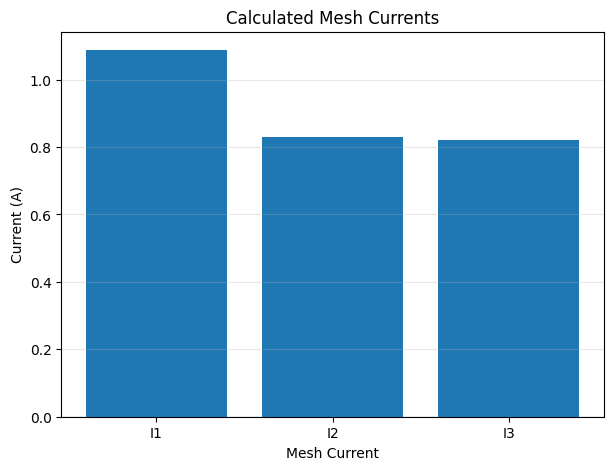

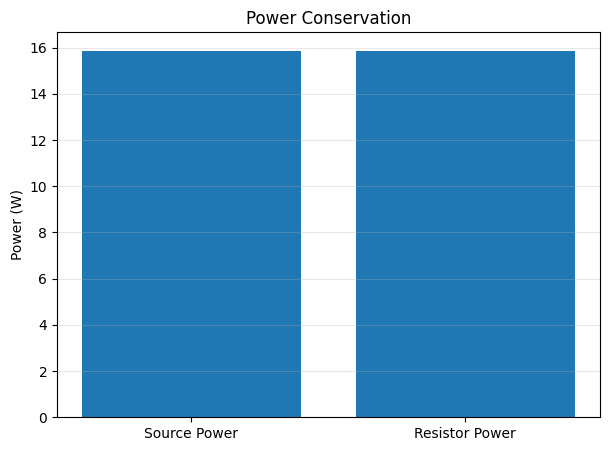

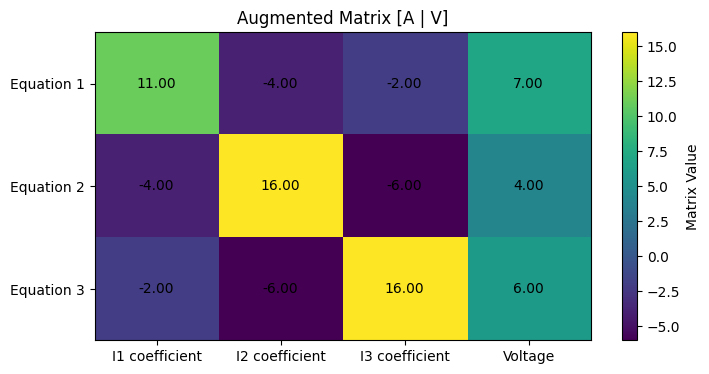


       KIRCHHOFF'S CIRCUIT SOLVER COMPLETED ✓


In [ ]:
3# ============================================================
# KIRCHHOFF'S CIRCUIT SOLVER - USER INPUT VERSION
# ============================================================

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

print("=" * 65)
print("        KIRCHHOFF'S CIRCUIT SOLVER")
print("=" * 65)
print("Enter the circuit values below.")
print("All resistances are in Ohms (Ω) and voltages are in Volts (V).\n")

# ------------------------------------------------------------
# 1. GET INPUT FROM USER
# ------------------------------------------------------------

def get_positive_number(message):
    while True:
        try:
            value = float(input(message))
            if value < 0:
                print("Please enter a non-negative value.")
            else:
                return value
        except ValueError:
            print("Invalid input! Please enter a number.")


print("RESISTANCE VALUES")
print("-" * 40)

R1 = get_positive_number("Enter R1  (Ω): ")
R2 = get_positive_number("Enter R2  (Ω): ")
R3 = get_positive_number("Enter R3  (Ω): ")

R12 = get_positive_number("Enter R12 (Ω): ")
R23 = get_positive_number("Enter R23 (Ω): ")
R13 = get_positive_number("Enter R13 (Ω): ")

print("\nVOLTAGE SOURCE VALUES")
print("-" * 40)

V1 = float(input("Enter V1 (V): "))
V2 = float(input("Enter V2 (V): "))
V3 = float(input("Enter V3 (V): "))

V = np.array([V1, V2, V3], dtype=float)

# ------------------------------------------------------------
# 2. DISPLAY USER INPUT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("                 INPUT VALUES")
print("=" * 65)

print(f"R1  = {R1:.2f} Ω")
print(f"R2  = {R2:.2f} Ω")
print(f"R3  = {R3:.2f} Ω")
print(f"R12 = {R12:.2f} Ω")
print(f"R23 = {R23:.2f} Ω")
print(f"R13 = {R13:.2f} Ω")

print(f"V1  = {V1:.2f} V")
print(f"V2  = {V2:.2f} V")
print(f"V3  = {V3:.2f} V")

# ------------------------------------------------------------
# 3. MATHEMATICAL MODEL
# ------------------------------------------------------------
#
# Assumption:
# Three clockwise mesh currents I1, I2 and I3 are used.
#
# For a shared resistor:
# Branch current = difference of adjacent mesh currents.
#
# The equations are:
#
# (R1+R12+R13)I1 - R12 I2 - R13 I3 = V1
#
# -R12 I1 + (R2+R12+R23)I2 - R23 I3 = V2
#
# -R13 I1 - R23 I2 + (R3+R23+R13)I3 = V3
# ------------------------------------------------------------

A = np.array([
    [R1 + R12 + R13, -R12, -R13],
    [-R12, R2 + R12 + R23, -R23],
    [-R13, -R23, R3 + R23 + R13]
], dtype=float)

# ------------------------------------------------------------
# 4. DISPLAY KVL EQUATIONS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("                 KVL EQUATIONS")
print("=" * 65)

print(
    f"{A[0,0]:.2f}I1 {A[0,1]:+.2f}I2 {A[0,2]:+.2f}I3 = {V1:.2f}"
)

print(
    f"{A[1,0]:+.2f}I1 {A[1,1]:+.2f}I2 {A[1,2]:+.2f}I3 = {V2:.2f}"
)

print(
    f"{A[2,0]:+.2f}I1 {A[2,1]:+.2f}I2 {A[2,2]:+.2f}I3 = {V3:.2f}"
)

# ------------------------------------------------------------
# 5. CREATE AUGMENTED MATRIX
# ------------------------------------------------------------

augmented_matrix = np.column_stack((A, V))

print("\n" + "=" * 65)
print("              AUGMENTED MATRIX [A | V]")
print("=" * 65)

print(np.round(augmented_matrix, 4))

# ------------------------------------------------------------
# 6. GAUSS-JORDAN ELIMINATION
# ------------------------------------------------------------

def gauss_jordan(matrix):

    M = np.array(matrix, dtype=float).copy()
    rows, columns = M.shape

    for pivot in range(rows):

        # Find the largest pivot
        max_row = pivot + np.argmax(
            np.abs(M[pivot:, pivot])
        )

        # Swap rows
        M[[pivot, max_row]] = M[[max_row, pivot]]

        # Check for zero pivot
        if abs(M[pivot, pivot]) < 1e-12:
            raise ValueError(
                "The circuit does not have a unique solution."
            )

        # Make pivot equal to 1
        M[pivot] = M[pivot] / M[pivot, pivot]

        # Make all other values in pivot column zero
        for row in range(rows):

            if row != pivot:

                factor = M[row, pivot]

                M[row] = M[row] - factor * M[pivot]

    return M


# Solve the system
rref = gauss_jordan(augmented_matrix)

print("\n" + "=" * 65)
print("              GAUSS-JORDAN RREF")
print("=" * 65)

print(np.round(rref, 6))

# ------------------------------------------------------------
# 7. GET CURRENT VALUES
# ------------------------------------------------------------

currents = rref[:, -1]

I1, I2, I3 = currents

print("\n" + "=" * 65)
print("                 CIRCUIT CURRENTS")
print("=" * 65)

print(f"I1 = {I1:.6f} A")
print(f"I2 = {I2:.6f} A")
print(f"I3 = {I3:.6f} A")

# ------------------------------------------------------------
# 8. SYMPY VERIFICATION
# ------------------------------------------------------------

A_sym = sp.Matrix(A)
V_sym = sp.Matrix(V)

solution = A_sym.LUsolve(V_sym)

print("\n" + "=" * 65)
print("                SYMPY VERIFICATION")
print("=" * 65)

print(f"I1 = {float(solution[0]):.6f} A")
print(f"I2 = {float(solution[1]):.6f} A")
print(f"I3 = {float(solution[2]):.6f} A")

# ------------------------------------------------------------
# 9. KVL VERIFICATION
# ------------------------------------------------------------

calculated_voltage = A @ currents

voltage_error = calculated_voltage - V

max_voltage_error = np.max(
    np.abs(voltage_error)
)

print("\n" + "=" * 65)
print("                 KVL VERIFICATION")
print("=" * 65)

for i in range(3):

    print(
        f"Equation {i+1}: "
        f"Calculated = {calculated_voltage[i]:.6f} V | "
        f"Expected = {V[i]:.6f} V"
    )

print(
    f"\nMaximum KVL Error = "
    f"{max_voltage_error:.12f} V"
)

if max_voltage_error < 1e-9:
    print("KVL CHECK: PASSED ✓")
else:
    print("KVL CHECK: FAILED ✗")

# ------------------------------------------------------------
# 10. BRANCH CURRENTS
# ------------------------------------------------------------

IR1 = I1
IR2 = I2
IR3 = I3

IR12 = I1 - I2
IR23 = I2 - I3
IR13 = I1 - I3

print("\n" + "=" * 65)
print("               BRANCH CURRENTS")
print("=" * 65)

print(f"R1  current  = {IR1:.6f} A")
print(f"R2  current  = {IR2:.6f} A")
print(f"R3  current  = {IR3:.6f} A")
print(f"R12 current  = {IR12:.6f} A")
print(f"R23 current  = {IR23:.6f} A")
print(f"R13 current  = {IR13:.6f} A")

# ------------------------------------------------------------
# 11. POWER CALCULATION
# ------------------------------------------------------------

P1 = IR1**2 * R1
P2 = IR2**2 * R2
P3 = IR3**2 * R3

P12 = IR12**2 * R12
P23 = IR23**2 * R23
P13 = IR13**2 * R13

total_resistor_power = (
    P1 + P2 + P3 +
    P12 + P23 + P13
)

source_power = V @ currents

power_difference = (
    source_power -
    total_resistor_power
)

print("\n" + "=" * 65)
print("                 POWER ANALYSIS")
print("=" * 65)

print(f"Power in R1  = {P1:.6f} W")
print(f"Power in R2  = {P2:.6f} W")
print(f"Power in R3  = {P3:.6f} W")
print(f"Power in R12 = {P12:.6f} W")
print(f"Power in R23 = {P23:.6f} W")
print(f"Power in R13 = {P13:.6f} W")

print(
    f"\nTotal resistor power = "
    f"{total_resistor_power:.6f} W"
)

print(
    f"Source power supplied = "
    f"{source_power:.6f} W"
)

print(
    f"Power difference = "
    f"{power_difference:.12f} W"
)

if abs(power_difference) < 1e-9:
    print("POWER CONSERVATION: PASSED ✓")
else:
    print("POWER CONSERVATION: FAILED ✗")

# ------------------------------------------------------------
# 12. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("                    FINAL RESULT")
print("=" * 65)

print(f"I1 = {I1:.6f} A")
print(f"I2 = {I2:.6f} A")
print(f"I3 = {I3:.6f} A")

if (
    max_voltage_error < 1e-9
    and abs(power_difference) < 1e-9
):
    print("\nOVERALL STATUS: SUCCESS ✓")
    print("The circuit has been solved and verified.")
else:
    print("\nOVERALL STATUS: CHECK INPUTS ✗")

# ------------------------------------------------------------
# 13. CURRENT GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["I1", "I2", "I3"],
    [I1, I2, I3]
)

plt.axhline(0, linewidth=0.8)

plt.title("Calculated Mesh Currents")
plt.xlabel("Mesh Current")
plt.ylabel("Current (A)")
plt.grid(axis="y", alpha=0.3)

plt.show()

# ------------------------------------------------------------
# 14. POWER GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["Source Power", "Resistor Power"],
    [source_power, total_resistor_power]
)

plt.title("Power Conservation")
plt.ylabel("Power (W)")
plt.grid(axis="y", alpha=0.3)

plt.show()

# ------------------------------------------------------------
# 15. AUGMENTED MATRIX GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

plt.imshow(
    augmented_matrix,
    aspect="auto"
)

plt.colorbar(label="Matrix Value")

plt.xticks(
    range(4),
    ["I1 coefficient",
     "I2 coefficient",
     "I3 coefficient",
     "Voltage"]
)

plt.yticks(
    range(3),
    ["Equation 1",
     "Equation 2",
     "Equation 3"]
)

plt.title("Augmented Matrix [A | V]")

for i in range(3):

    for j in range(4):

        plt.text(
            j,
            i,
            f"{augmented_matrix[i,j]:.2f}",
            ha="center",
            va="center"
        )

plt.show()

print("\n" + "=" * 65)
print("       KIRCHHOFF'S CIRCUIT SOLVER COMPLETED ✓")
print("=" * 65)